Community detection in Karate Club graph using modularity

Pranav P Vasudevan - IMS25291

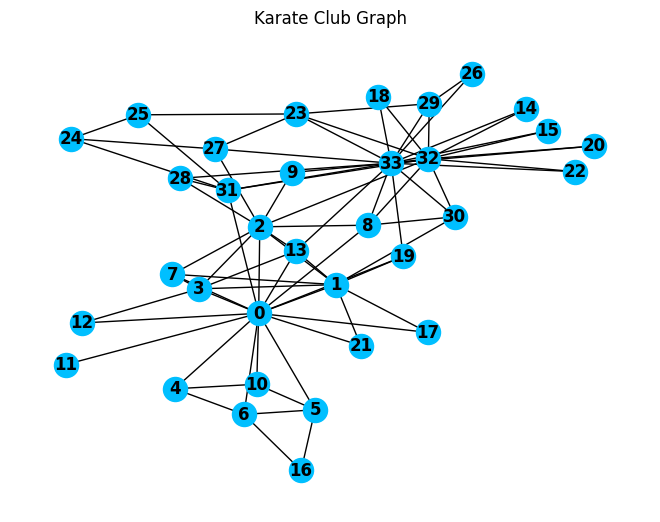

In [14]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

nx.set_edge_attributes(G, 1, 'weight') #set graph weight to 1

layout_seed = 67

nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), with_labels=True, node_color="deepskyblue", font_weight="bold")
plt.title("Karate Club Graph")
plt.show()


**Calculating graph parameters **

A is the adjacency matrix, B is the modularity matrix and Bc is the restricted modularity matrix.



In [15]:
def adj(Gi):
  Ai = nx.to_numpy_array(Gi)    # (P, P)
  return Ai

def modul(G):
  A = adj(G)

  d = dict(G.degree) #getting degrees


  m = sum(list(d.values()))/2  #sum of degrees is 2m


  kT = np.array([list(d.values())])
  k = kT.T #changing up the order

  #calculating the modularity matrix
  B = A - (k@kT)/(2*m)

  return B

def rmodul(Gi, A):
  # A is the original graph adjacency matrix
  # Gi is any sub divided graph component of it
  # Assuming Gi has P vertices, B(C) is returned where C
  # is the community represented by Gi and is of dimension PxP
  P = len(Gi)
  m = A.sum()/2

  Bci = np.zeros((P, P))

  for i1, n1 in enumerate(list(Gi.nodes)):
    k1 = np.sum(A[n1])
    for i2, n2 in enumerate(list(Gi.nodes)[i1+1:], start=i1+1):
      k2 = np.sum(A[n2])

      v = A[n1][n2] - (k1*k2)/(2*m)
      Bci[i1][i2] = v
      Bci[i2][i1] = v

    Bci[i1][i1] = -(k1*k1)/(2*m)

  Bci = Bci - np.diag(Bci.sum(axis=1))

  return Bci


**Partition function**

for a subgraph G this function checks if parititioning the subgraph is a good decision by evaluating deltaQ score, scores very near to zero are taken to be zero.

In [16]:

def splitting(x):  #function to convert fuzzy split values to -1 or 1
  if x > 0:
    return 1
  else:
    return -1

def partition(Gi, Bci, m):
  if len(Gi) <= 1:
    return False, False, False


  Ai = adj(Gi)  #adjacency matrix for any subgraph Gi
  evals, evecs = np.linalg.eigh(Bci)


  max_eval_i = np.argmax(evals)
  max_eval = evals[max_eval_i]  #max eigenvalue

  max_evec = evecs[:, max_eval_i]  #leading eigenvector

  s = [splitting(x) for x in max_evec]

  S = np.array([s])

  Q = (S@Bci@S.T)/(4*m) #Q is modularity score


  if abs(Q) < 1e-5:
    Q = 0

  if Q <= 0:
    return False, False, False   #if Q is lesser than zero, it makes no sense to partition

  Gi1 = nx.Graph()  #subgraph 1
  Gi2 = nx.Graph()  #subgraph 2

  for i1, n1 in enumerate(list(Gi.nodes)):
    group_n1 = s[i1]
    if group_n1 == -1:
      Gi1.add_node(n1)
    else:
      Gi2.add_node(n1)

    for i2, n2 in enumerate(list(Gi.nodes)[i1+1:], start=i1+1):
      group_n2 = s[i2]
      con = Ai[i1][i2]

      if group_n1 == group_n2 and con == 1:
        if group_n1 == -1:
            Gi1.add_edge(n2, n1, weight=1)
        else:
            Gi2.add_edge(n2, n1, weight=1)

  return Gi1, Gi2, Q

**Recursive splitting algorithm**

we use this function inside a recursive algorithm that keeps partitioning until it becomes unfavorable to do so .

This is done along for each partition as newly created sub graphs are added to the C (Community) list, and the old graph that was subdivided is removed.
old one is stored in temp folder

In [17]:

def recursive_partition(C, C_timeline, Gi, Bi, A, depth=1, maxdepth=10):
  m = A.sum()/2
  Gi1, Gi2, Q = partition(Gi, Bi, m)


  if Gi1 == False:  #we cannot partition
    print("(end)")
    return

  C.append(Gi1)  #c is the community list
  C.append(Gi2)

  if Gi in C:
    C.remove(Gi)


  C_timeline.append(C.copy())  #storing the first partition as temp


  Bi1 = rmodul(Gi1, A)
  Bi2 = rmodul(Gi2, A)

  if maxdepth == depth:
    print(" "*depth, Gi1, f"Q:{Q}", "(end)")
    print(" "*depth, Gi2, f"Q:{Q}", "(end)")
  else:
    print(" "*depth, Gi1, f"Q:{Q}")
    recursive_partition(C, C_timeline, Gi1, Bi1, A, depth=depth+1, maxdepth=maxdepth)
    print(" "*depth, Gi2, f"Q:{Q}")
    recursive_partition(C, C_timeline, Gi2, Bi2, A, depth=depth+1, maxdepth=maxdepth)

For each parition iteration output, we calculating the following parameters

1. Degree centrality
2. Betweenness centrality
3. Closeness centrality
4. Clustering coefficient


In [18]:
def get_metrics(G, C_timeline):
  metrics = {}
  metrics[0] = {"D":{}, "B":{}, "C":{}, "K":{}}

  # Initial state
  d = nx.degree_centrality(G)
  b = nx.betweenness_centrality(G)
  c = nx.closeness_centrality(G)
  k = nx.clustering(G)
  metrics[0]["D"][0] = d
  metrics[0]["B"][0] = b
  metrics[0]["C"][0] = c
  metrics[0]["K"][0] = k

  for Ci, C in enumerate(C_timeline):
    # Community list will have each node exactly once, in some group

    # D - Degree Centrality
    # B - Betweenness Centrality
    # C - Closeness Centrality
    # K - Clustering Coefficient
    metrics[Ci+1] = {"D":{}, "B":{}, "C":{}, "K":{}}

    for Gi, G in enumerate(C):

      d = nx.degree_centrality(G)
      b = nx.betweenness_centrality(G)
      c = nx.closeness_centrality(G)
      k = nx.clustering(G)
      metrics[Ci+1]["D"][Gi] = d
      metrics[Ci+1]["B"][Gi] = b
      metrics[Ci+1]["C"][Gi] = c
      metrics[Ci+1]["K"][Gi] = k

  return metrics

Now we plot the metrics for each split graph (all the iterations)
each community is given a unique color


  Graph with 18 nodes and 35 edges Q:[[0.37146614]]
   Graph with 6 nodes and 7 edges Q:[[0.02071006]]
(end)
   Graph with 12 nodes and 21 edges Q:[[0.02071006]]
(end)
  Graph with 16 nodes and 33 edges Q:[[0.37146614]]
   Graph with 9 nodes and 13 edges Q:[[0.00123274]]
(end)
   Graph with 7 nodes and 11 edges Q:[[0.00123274]]
(end)


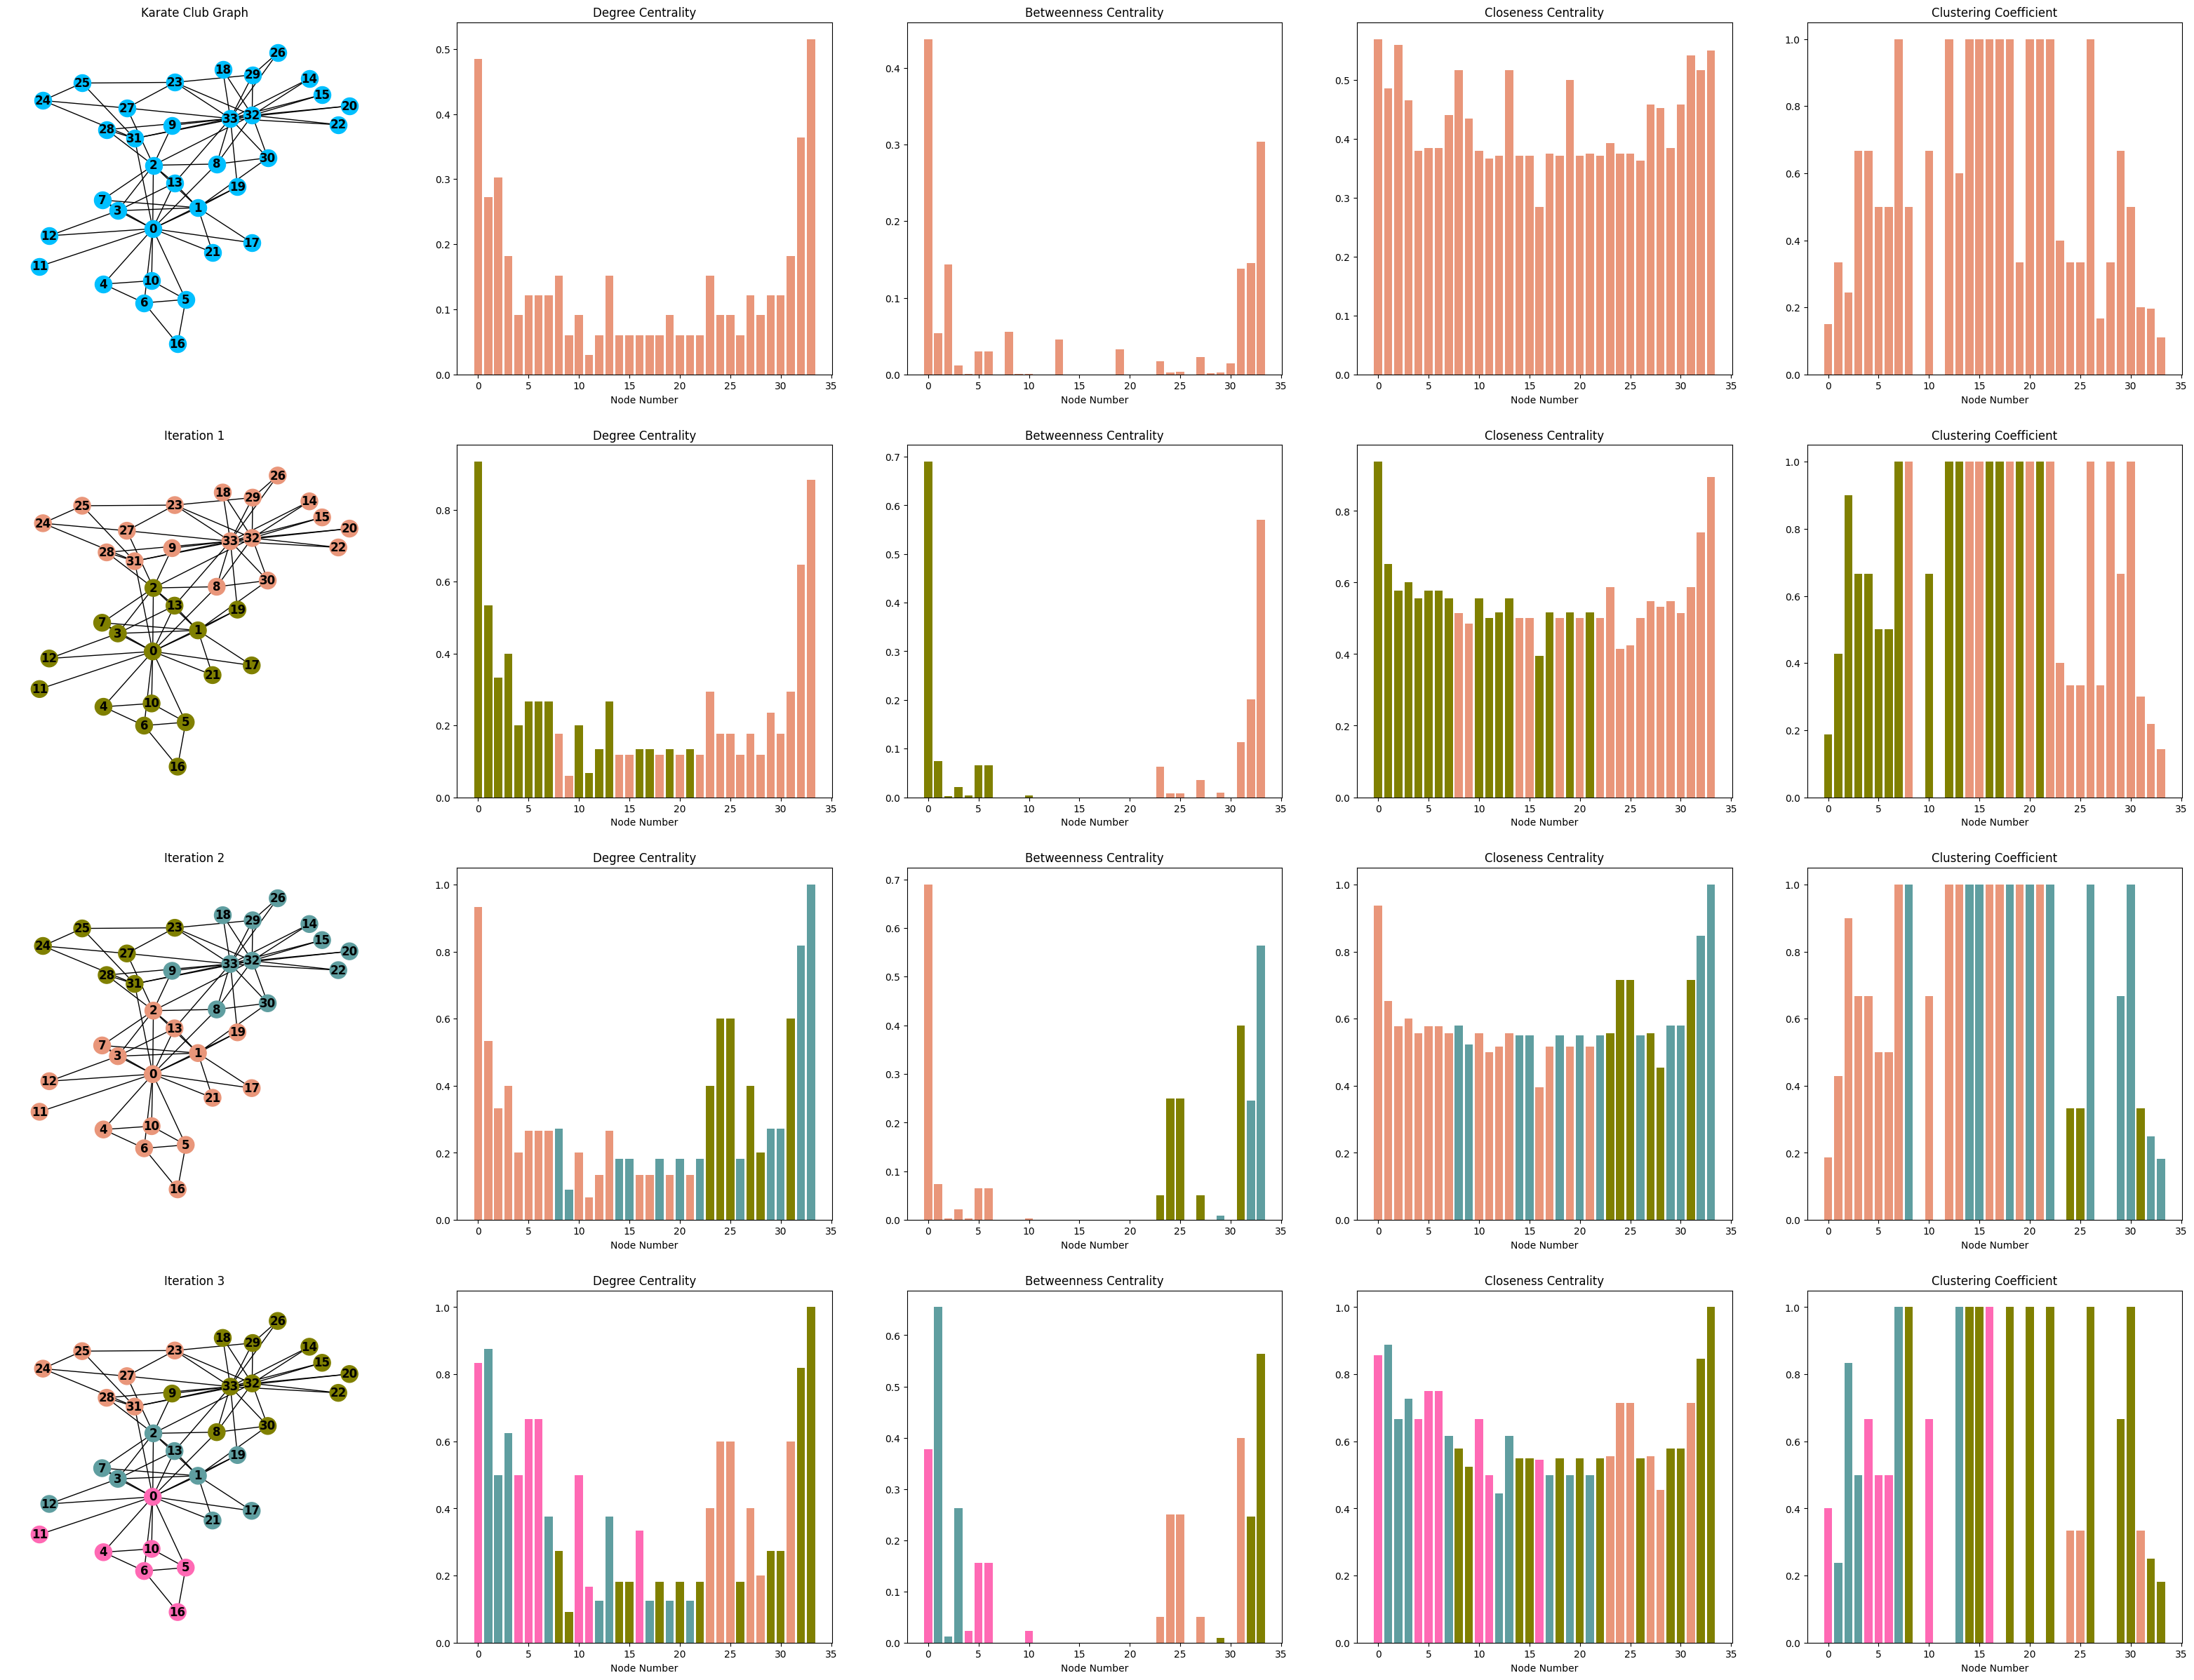

In [19]:
colors = ["darksalmon", "olive", "cadetblue", "hotpink"]

# Final list of partitioned communities
C = []
# Timeline metadata
C_timeline = []

A = adj(G)
B = modul(G)

recursive_partition(C, C_timeline, G, B, A, maxdepth=10)

metrics = get_metrics(G, C_timeline)

# Create a nx1 grid of subplots
fig, axes = plt.subplots(nrows=len(C), ncols=5, figsize=(40, 30))

axes[0][0].set_title("Karate Club Graph")
nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), ax=axes[0][0], with_labels=True, node_color="deepskyblue", font_weight="bold")

for Ci, C in enumerate(C_timeline):
  color_map = []

  for i in range(len(G)):
    for j in range(len(C)):
      if i in C[j]:
        color_map.append(colors[j])
        break

  axes[Ci+1][0].set_title(f"Iteration {Ci+1}")
  nx.draw(G, pos=nx.spring_layout(G, seed=layout_seed), ax=axes[Ci+1][0], with_labels=True, node_color=color_map, font_weight="bold")

for it, M in metrics.items():


  plots = {"D":"Degree Centrality", "B":"Betweenness Centrality", "C":"Closeness Centrality", "K":"Clustering Coefficient"}

  for name_i, name in enumerate(plots.keys()):
    ax = axes[it][name_i+1]

    for Gi, d in M[name].items():
      cats = d.keys()
      vals = d.values()
      ax.set_title(plots[name])
      ax.set_xlabel("Node Number")

      ax.bar(cats, vals, color=colors[Gi])

plt.show()


**Discussion**

We observe that the Karate club graph splits in 4 communities, the algorithm not splitting it into further communities suggests that beyond 4 communities, the splitting is no better than making a random split

For nodes 0, 1, 31, 32, 33
 1. These act as strong hubs and connectors in the original graph (high Betweenness Centrality)

 2. They have high no. of nodes connected to them in absolute terms (high Degree Centrality)

 3. They can reach other nodes quickly and have low average shortest path distance (high Closeness Centrality)

They also have low Clustering Coefficient compared to other nodes as due to having high no. of connected nodes and centrality, the likelihood of its connected nodes being connected to each other decreases

**References**

Newman (2006), “Modularity and community structure in networks,”